# Advanced Multi-Source Data Pipeline Scrape

In [3]:
import requests
from bs4 import BeautifulSoup
import json
from dotenv import load_dotenv
import pandas as pd
import numpy as np
import os
import time 

In [4]:
pip install beautifulsoup4 requests pandas load_dotenv

Note: you may need to restart the kernel to use updated packages.


In [5]:
load_dotenv()

api_key = os.getenv("cryptocurrency_market_api_key")

url = "https://api.coingecko.com/api/v3/coins/markets"

headers = {
    "x-cg-demo-api-key": api_key
}

all_data = []

for page in range(1, 6):

    params = {
        "vs_currency": "usd",
        "order": "market_cap_desc",
        "per_page": 100,
        "page": page
    }

    response = requests.get(
        url,
        params=params,
        headers=headers
    )

    print("Page:", page, "Status:", response.status_code)

    # Check if request was successful
    if response.status_code == 200:

        data = response.json()

        # Make sure data is a list
        if isinstance(data, list):
            all_data.extend(data)
        else:
            print("Unexpected response:", data)

    else:
        print("Error:", response.text)

    time.sleep(1)

df = pd.DataFrame(all_data)

print("Total rows:", len(df))
print(df.head())

Page: 1 Status: 200
Page: 2 Status: 200
Page: 3 Status: 200
Page: 4 Status: 200
Page: 5 Status: 200
Total rows: 500
            id symbol      name  \
0      bitcoin    btc   Bitcoin   
1     ethereum    eth  Ethereum   
2       tether   usdt    Tether   
3  binancecoin    bnb       BNB   
4       ripple    xrp       XRP   

                                               image  current_price  \
0  https://coin-images.coingecko.com/coins/images...   79759.000000   
1  https://coin-images.coingecko.com/coins/images...    2506.760000   
2  https://coin-images.coingecko.com/coins/images...       0.999884   
3  https://coin-images.coingecko.com/coins/images...     748.320000   
4  https://coin-images.coingecko.com/coins/images...       1.410000   

      market_cap  market_cap_rank  fully_diluted_valuation  total_volume  \
0  1601706680020              1.0             1.601710e+12  2.108560e+10   
1   305899211572              2.0             3.058992e+11  1.018079e+10   
2   183388129777  

In [6]:
df

,id,symbol,name,image,current_price,market_cap,market_cap_rank,fully_diluted_valuation,total_volume,high_24h,...,total_supply,max_supply,ath,ath_change_percentage,ath_date,atl,atl_change_percentage,atl_date,roi,last_updated
0,bitcoin,btc,Bitcoin,https://coin-images.coingecko.com/coins/images...,79759.000000,1601706680020,1.0,1.601710e+12,2.108560e+10,80494.000000,...,2.008081e+07,2.100000e+07,126080.000000,-36.73900,2025-10-06T10:57:42.000Z,67.810000,1.175236e+05,2013-07-05T16:00:00.000Z,None,2026-09-07T03:17:20.000Z
1,ethereum,eth,Ethereum,https://coin-images.coingecko.com/coins/images...,2506.760000,305899211572,2.0,3.058992e+11,1.018079e+10,2532.720000,...,1.220268e+08,NaN,4946.050000,-49.31786,2025-08-24T11:21:03.000Z,0.432979,5.788574e+05,2015-10-19T16:00:00.000Z,"{'times': 41.02614095486372, 'currency': 'btc'...",2026-09-07T03:17:20.000Z
2,tether,usdt,Tether,https://coin-images.coingecko.com/coins/images...,0.999884,183388129777,3.0,1.888544e+11,4.559961e+10,1.000000,...,1.888777e+11,NaN,1.320000,-24.42839,2018-07-23T16:00:00.000Z,0.572521,7.464590e+01,2015-03-01T16:00:00.000Z,None,2026-09-07T03:17:20.000Z
3,binancecoin,bnb,BNB,https://coin-images.coingecko.com/coins/images...,748.320000,99647523307,4.0,9.964752e+10,1.131655e+09,764.980000,...,1.331618e+08,2.000000e+08,1369.990000,-45.37758,2025-10-13T00:41:24.000Z,0.039818,1.879272e+06,2017-10-18T16:00:00.000Z,None,2026-09-07T03:17:20.000Z
4,ripple,xrp,XRP,https://coin-images.coingecko.com/coins/images...,1.410000,88433777870,5.0,1.409224e+11,1.600707e+09,1.430000,...,9.998563e+10,1.000000e+11,3.650000,-61.35471,2025-07-17T19:40:53.000Z,0.002686,5.235885e+04,2014-05-21T16:00:00.000Z,None,2026-09-07T03:17:20.000Z
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495,lombard-protocol,bard,Lombard,https://coin-images.coingecko.com/coins/images...,0.134135,47393137,483.0,1.340920e+08,2.387626e+06,0.133711,...,1.000000e+09,1.000000e+09,1.700000,-92.11264,2026-03-05T12:26:18.000Z,0.100524,3.343593e+01,2026-08-18T03:33:40.000Z,None,2026-09-07T03:18:20.000Z
496,dappos,dos,DAPPOS,https://coin-images.coingecko.com/coins/images...,0.237935,47379883,484.0,2.368994e+08,5.441963e+06,0.245021,...,1.000000e+09,1.000000e+09,1.430000,-83.31899,2026-08-10T10:35:50.000Z,0.206958,1.496750e+01,2026-08-22T05:11:50.000Z,None,2026-09-07T03:18:20.000Z
497,jupusd,jupusd,JupUSD,https://coin-images.coingecko.com/coins/images...,0.999502,47307396,485.0,4.730740e+07,1.836962e+07,0.999810,...,4.733075e+07,NaN,1.023000,-2.33897,2026-04-26T05:01:00.000Z,0.124871,7.004258e+02,2026-07-09T09:10:50.000Z,None,2026-09-07T03:18:20.000Z
498,concordium,ccd,Concordium,https://coin-images.coingecko.com/coins/images...,0.003707,47104175,486.0,5.428629e+07,1.060360e+05,0.003987,...,1.464346e+10,NaN,0.149407,-97.51909,2022-02-10T04:22:15.000Z,0.002623,4.131030e+01,2024-07-15T17:52:20.000Z,None,2026-09-07T03:18:20.000Z


In [7]:
df.shape

(500, 26)

In [8]:
df.isna().sum()

id                                    0
symbol                                0
name                                  0
image                                 0
current_price                         0
market_cap                            0
market_cap_rank                       2
fully_diluted_valuation               0
total_volume                          0
high_24h                              0
low_24h                               0
price_change_24h                     14
price_change_percentage_24h          14
market_cap_change_24h                14
market_cap_change_percentage_24h     14
circulating_supply                    0
total_supply                          0
max_supply                          206
ath                                   0
ath_change_percentage                 0
ath_date                              0
atl                                   0
atl_change_percentage                 0
atl_date                              0
roi                                 460


In [9]:
df.columns

Index(['id', 'symbol', 'name', 'image', 'current_price', 'market_cap',
       'market_cap_rank', 'fully_diluted_valuation', 'total_volume',
       'high_24h', 'low_24h', 'price_change_24h',
       'price_change_percentage_24h', 'market_cap_change_24h',
       'market_cap_change_percentage_24h', 'circulating_supply',
       'total_supply', 'max_supply', 'ath', 'ath_change_percentage',
       'ath_date', 'atl', 'atl_change_percentage', 'atl_date', 'roi',
       'last_updated'],
      dtype='str')

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 26 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   id                                500 non-null    str    
 1   symbol                            500 non-null    str    
 2   name                              500 non-null    str    
 3   image                             500 non-null    str    
 4   current_price                     500 non-null    float64
 5   market_cap                        500 non-null    int64  
 6   market_cap_rank                   498 non-null    float64
 7   fully_diluted_valuation           500 non-null    float64
 8   total_volume                      500 non-null    float64
 9   high_24h                          500 non-null    float64
 10  low_24h                           500 non-null    float64
 11  price_change_24h                  486 non-null    float64
 12  price_change_percen

In [11]:
df['market_cap_rank'] = df['market_cap_rank'].fillna(df['market_cap_rank'].mean())

In [12]:
df['market_cap_rank'].isna().sum()

np.int64(0)

In [13]:
df['price_change_24h'] = df['price_change_24h'].fillna(df['price_change_24h'].mean())
df['price_change_24h'].isna().sum()

np.int64(0)

In [14]:
df['price_change_percentage_24h'] = df['price_change_percentage_24h'].fillna(df['price_change_percentage_24h'].mean())
df['price_change_percentage_24h'].isna().sum()

np.int64(0)

In [15]:
df.isna().sum()

id                                    0
symbol                                0
name                                  0
image                                 0
current_price                         0
market_cap                            0
market_cap_rank                       0
fully_diluted_valuation               0
total_volume                          0
high_24h                              0
low_24h                               0
price_change_24h                      0
price_change_percentage_24h           0
market_cap_change_24h                14
market_cap_change_percentage_24h     14
circulating_supply                    0
total_supply                          0
max_supply                          206
ath                                   0
ath_change_percentage                 0
ath_date                              0
atl                                   0
atl_change_percentage                 0
atl_date                              0
roi                                 460


In [16]:
df['market_cap_change_24h'] = df['market_cap_change_24h'].fillna(df['market_cap_change_24h'].mean())
df['market_cap_change_24h'].isna().sum()

np.int64(0)

In [17]:
df['market_cap_change_percentage_24h'] = df['market_cap_change_percentage_24h'].fillna(df['market_cap_change_percentage_24h'].mean())
df['market_cap_change_percentage_24h'].isna().sum()

np.int64(0)

In [18]:
df['max_supply'] = df['max_supply'].fillna(df['max_supply'].mean())
df['max_supply'].isna().sum()

np.int64(0)

In [19]:
df['roi'] = df['roi'].fillna(df['roi'].mode())
df['roi'].isna().sum()

C:\Users\anilr\AppData\Local\Temp\ipykernel_23496\966367544.py:1: UserWarning: Unable to sort modes: '<' not supported between instances of 'dict' and 'dict'
  df['roi'] = df['roi'].fillna(df['roi'].mode())


np.int64(422)

In [20]:
df['roi'].value_counts()

roi
{'times': 41.02614095486372, 'currency': 'btc', 'percentage': 4102.614095486372}         2
{'times': 16.360882744001856, 'currency': 'usd', 'percentage': 1636.0882744001856}       2
{'times': 10.424497483923718, 'currency': 'eth', 'percentage': 1042.4497483923717}       2
{'times': -0.96063118134478, 'currency': 'usd', 'percentage': -96.063118134478}          2
{'times': 14.92232531275027, 'currency': 'usd', 'percentage': 1492.232531275027}         2
{'times': 7.38493455233221, 'currency': 'usd', 'percentage': 738.493455233221}           2
{'times': -0.6844731770445742, 'currency': 'usd', 'percentage': -68.44731770445742}      2
{'times': 0.4997144773375851, 'currency': 'eth', 'percentage': 49.97144773375851}        2
{'times': 1.1628947978173434, 'currency': 'usd', 'percentage': 116.28947978173433}       2
{'times': 0.9933631708578143, 'currency': 'usd', 'percentage': 99.33631708578143}        2
{'times': -0.4960691410819698, 'currency': 'usd', 'percentage': -49.60691410819698}   

In [21]:
print(df['roi'].head())
print(df['roi'].dtype)

0    {'times': 41.02614095486372, 'currency': 'btc'...
1    {'times': 41.02614095486372, 'currency': 'btc'...
2    {'times': 16.360882744001856, 'currency': 'usd...
3    {'times': 10.424497483923718, 'currency': 'eth...
4    {'times': -0.96063118134478, 'currency': 'usd'...
Name: roi, dtype: object
object


In [22]:
mode_value = df['roi'].mode().iloc[0]
df['roi'] = df['roi'].fillna(mode_value)

C:\Users\anilr\AppData\Local\Temp\ipykernel_23496\519123216.py:1: UserWarning: Unable to sort modes: '<' not supported between instances of 'dict' and 'dict'
  mode_value = df['roi'].mode().iloc[0]


In [23]:
print(df['roi'].head())
print(df['roi'].dtype)

0    {'times': 41.02614095486372, 'currency': 'btc'...
1    {'times': 41.02614095486372, 'currency': 'btc'...
2    {'times': 16.360882744001856, 'currency': 'usd...
3    {'times': 10.424497483923718, 'currency': 'eth...
4    {'times': -0.96063118134478, 'currency': 'usd'...
Name: roi, dtype: object
object


In [24]:
# Convert dictionaries to strings temporarily
roi_temp = df['roi'].apply(lambda x: str(x) if isinstance(x, dict) else x)

# Find the mode
roi_mode = roi_temp.mode()[0]

# Replace null values with the mode
df['roi'] = df['roi'].fillna(roi_mode)

In [25]:
df['roi'].isna().sum()

np.int64(0)

In [26]:
# converting atl_date col to date and time

df["atl_date"] = pd.to_datetime(df["atl_date"])
df["atl_date"].head()

0   2013-07-05 16:00:00+00:00
1   2015-10-19 16:00:00+00:00
2   2015-03-01 16:00:00+00:00
3   2017-10-18 16:00:00+00:00
4   2014-05-21 16:00:00+00:00
Name: atl_date, dtype: datetime64[us, UTC]

In [27]:
df.columns

Index(['id', 'symbol', 'name', 'image', 'current_price', 'market_cap',
       'market_cap_rank', 'fully_diluted_valuation', 'total_volume',
       'high_24h', 'low_24h', 'price_change_24h',
       'price_change_percentage_24h', 'market_cap_change_24h',
       'market_cap_change_percentage_24h', 'circulating_supply',
       'total_supply', 'max_supply', 'ath', 'ath_change_percentage',
       'ath_date', 'atl', 'atl_change_percentage', 'atl_date', 'roi',
       'last_updated'],
      dtype='str')

In [28]:
# converting ath_date col to date and time

df["ath_date"] = pd.to_datetime(df["ath_date"])
df["ath_date"].head()

0   2025-10-06 10:57:42+00:00
1   2025-08-24 11:21:03+00:00
2   2018-07-23 16:00:00+00:00
3   2025-10-13 00:41:24+00:00
4   2025-07-17 19:40:53+00:00
Name: ath_date, dtype: datetime64[us, UTC]

In [29]:
# converting last_updated col to date and time

df["last_updated"] = pd.to_datetime(df["last_updated"])
df["last_updated"].head()

0   2026-09-07 03:17:20+00:00
1   2026-09-07 03:17:20+00:00
2   2026-09-07 03:17:20+00:00
3   2026-09-07 03:17:20+00:00
4   2026-09-07 03:17:20+00:00
Name: last_updated, dtype: datetime64[us, UTC]

In [30]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 26 columns):
 #   Column                            Non-Null Count  Dtype              
---  ------                            --------------  -----              
 0   id                                500 non-null    str                
 1   symbol                            500 non-null    str                
 2   name                              500 non-null    str                
 3   image                             500 non-null    str                
 4   current_price                     500 non-null    float64            
 5   market_cap                        500 non-null    int64              
 6   market_cap_rank                   500 non-null    float64            
 7   fully_diluted_valuation           500 non-null    float64            
 8   total_volume                      500 non-null    float64            
 9   high_24h                          500 non-null    float64            
 10  l

In [31]:
df.isna().sum()

id                                  0
symbol                              0
name                                0
image                               0
current_price                       0
market_cap                          0
market_cap_rank                     0
fully_diluted_valuation             0
total_volume                        0
high_24h                            0
low_24h                             0
price_change_24h                    0
price_change_percentage_24h         0
market_cap_change_24h               0
market_cap_change_percentage_24h    0
circulating_supply                  0
total_supply                        0
max_supply                          0
ath                                 0
ath_change_percentage               0
ath_date                            0
atl                                 0
atl_change_percentage               0
atl_date                            0
roi                                 0
last_updated                        0
dtype: int64

In [32]:
df.to_csv("Advanced Multi-Source Data Pipeline Scrape.csv")

In [33]:
df.head()

,id,symbol,name,image,current_price,market_cap,market_cap_rank,fully_diluted_valuation,total_volume,high_24h,...,total_supply,max_supply,ath,ath_change_percentage,ath_date,atl,atl_change_percentage,atl_date,roi,last_updated
0,bitcoin,btc,Bitcoin,https://coin-images.coingecko.com/coins/images...,79759.000000,1601706680020,1.0,1.601710e+12,2.108560e+10,80494.00,...,2.008081e+07,2.100000e+07,126080.00,-36.73900,2025-10-06 10:57:42+00:00,67.810000,1.175236e+05,2013-07-05 16:00:00+00:00,"{'times': 41.02614095486372, 'currency': 'btc'...",2026-09-07 03:17:20+00:00
1,ethereum,eth,Ethereum,https://coin-images.coingecko.com/coins/images...,2506.760000,305899211572,2.0,3.058992e+11,1.018079e+10,2532.72,...,1.220268e+08,1.446644e+15,4946.05,-49.31786,2025-08-24 11:21:03+00:00,0.432979,5.788574e+05,2015-10-19 16:00:00+00:00,"{'times': 41.02614095486372, 'currency': 'btc'...",2026-09-07 03:17:20+00:00
2,tether,usdt,Tether,https://coin-images.coingecko.com/coins/images...,0.999884,183388129777,3.0,1.888544e+11,4.559961e+10,1.00,...,1.888777e+11,1.446644e+15,1.32,-24.42839,2018-07-23 16:00:00+00:00,0.572521,7.464590e+01,2015-03-01 16:00:00+00:00,"{'times': 16.360882744001856, 'currency': 'usd...",2026-09-07 03:17:20+00:00
3,binancecoin,bnb,BNB,https://coin-images.coingecko.com/coins/images...,748.320000,99647523307,4.0,9.964752e+10,1.131655e+09,764.98,...,1.331618e+08,2.000000e+08,1369.99,-45.37758,2025-10-13 00:41:24+00:00,0.039818,1.879272e+06,2017-10-18 16:00:00+00:00,"{'times': 10.424497483923718, 'currency': 'eth...",2026-09-07 03:17:20+00:00
4,ripple,xrp,XRP,https://coin-images.coingecko.com/coins/images...,1.410000,88433777870,5.0,1.409224e+11,1.600707e+09,1.43,...,9.998563e+10,1.000000e+11,3.65,-61.35471,2025-07-17 19:40:53+00:00,0.002686,5.235885e+04,2014-05-21 16:00:00+00:00,"{'times': -0.96063118134478, 'currency': 'usd'...",2026-09-07 03:17:20+00:00


In [34]:
pip install matplotlib seaborn

  Using cached matplotlib-3.11.1-cp314-cp314-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached contourpy-1.3.3-cp314-cp314-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.64.0-cp314-cp314-win_amd64.whl.metadata (126 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
Using cached matplotlib-3.11.1-cp314-cp314-win_amd64.whl (9.5 MB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached contourpy-1.3.3-cp314-cp314-win_amd64.whl (232 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.64.0-cp314-cp314-win_amd64.whl (2.5 MB)
Using cached kiwisolver-1.5.1-cp314-cp314-win_amd64.whl (72 kB)
Using cached pillow-12.3.0-cp314-cp314-win_amd64.whl (7.2 MB)
U

# 1. Cryptocurrency price distribution
Shows how current_price is distributed.

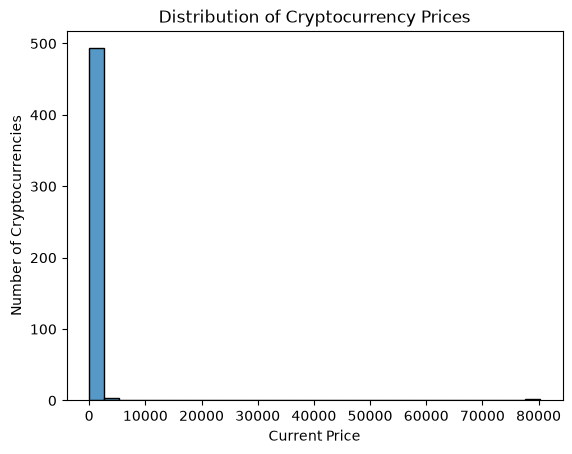

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(data=df, x='current_price', bins=30)
plt.title('Distribution of Cryptocurrency Prices')
plt.xlabel('Current Price')
plt.ylabel('Number of Cryptocurrencies')
plt.show()

# 2. Market Cap of top cryptocurrencies
Because market cap can be highly skewed, take the top 10/20.

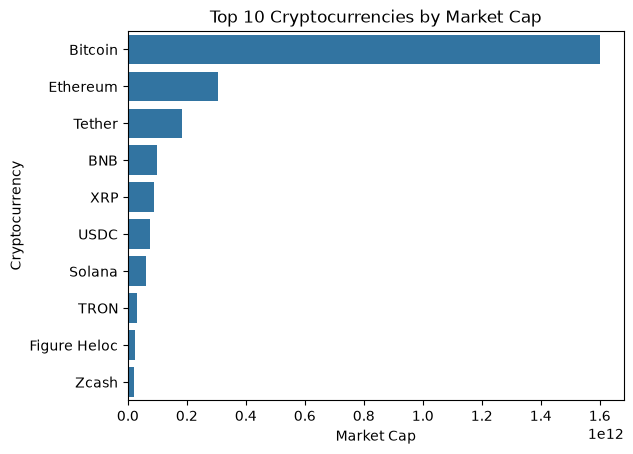

In [36]:
top_10 = df.nlargest(10, 'market_cap')

sns.barplot(data=top_10, x='market_cap', y='name')
plt.title('Top 10 Cryptocurrencies by Market Cap')
plt.xlabel('Market Cap')
plt.ylabel('Cryptocurrency')
plt.show()

# 3. Current Price vs Market Cap
Useful for understanding whether expensive coins also have high market capitalization.

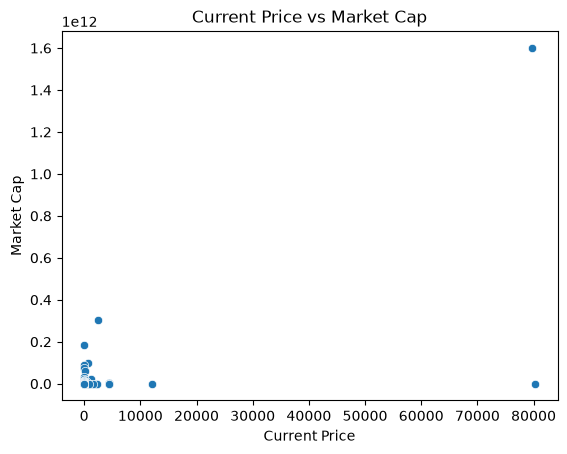

In [37]:
sns.scatterplot(
    data=df,
    x='current_price',
    y='market_cap'
)

plt.title('Current Price vs Market Cap')
plt.xlabel('Current Price')
plt.ylabel('Market Cap')
plt.show()

# 4. 24-hour price change

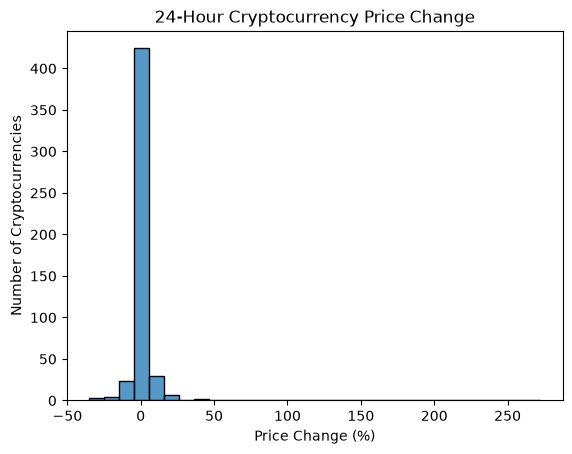

In [38]:
sns.histplot(
    data=df,
    x='price_change_percentage_24h',
    bins=30
)

plt.title('24-Hour Cryptocurrency Price Change')
plt.xlabel('Price Change (%)')
plt.ylabel('Number of Cryptocurrencies')
plt.show()

# 5. Top gainers and losers

For Top gainers

c:\Users\anilr\OneDrive\Desktop\Advanced_Multi-Source_Data_Pipeline\.venv-1\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 21704 (\N{CJK UNIFIED IDEOGRAPH-54C8}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\anilr\OneDrive\Desktop\Advanced_Multi-Source_Data_Pipeline\.venv-1\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 22522 (\N{CJK UNIFIED IDEOGRAPH-57FA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\anilr\OneDrive\Desktop\Advanced_Multi-Source_Data_Pipeline\.venv-1\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 31859 (\N{CJK UNIFIED IDEOGRAPH-7C73}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


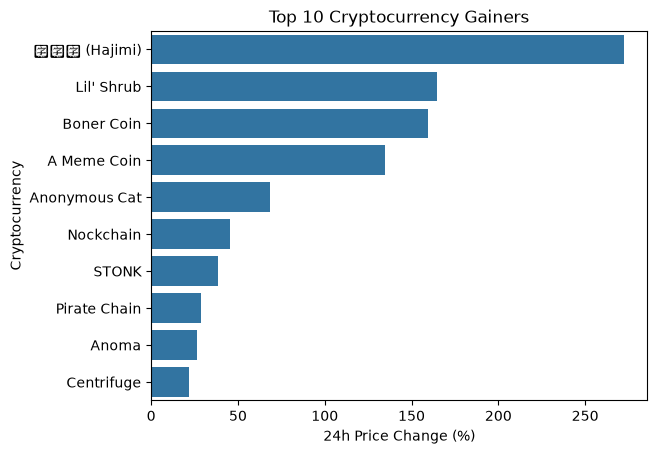

In [39]:
top_gainers = df.nlargest(10, 'price_change_percentage_24h')

sns.barplot(
    data=top_gainers,
    x='price_change_percentage_24h',
    y='name'
)

plt.title('Top 10 Cryptocurrency Gainers')
plt.xlabel('24h Price Change (%)')
plt.ylabel('Cryptocurrency')
plt.show()

For losers

c:\Users\anilr\OneDrive\Desktop\Advanced_Multi-Source_Data_Pipeline\.venv-1\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 29275 (\N{CJK UNIFIED IDEOGRAPH-725B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\anilr\OneDrive\Desktop\Advanced_Multi-Source_Data_Pipeline\.venv-1\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 26469 (\N{CJK UNIFIED IDEOGRAPH-6765}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\anilr\OneDrive\Desktop\Advanced_Multi-Source_Data_Pipeline\.venv-1\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 40857 (\N{CJK UNIFIED IDEOGRAPH-9F99}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\anilr\OneDrive\Desktop\Advanced_Multi-Source_Data_Pipeline\.venv-1\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 34430 (\N{CJK UNIFIED IDEOGRAPH-867E}) missing from font(s) DejaVu Sans.
  

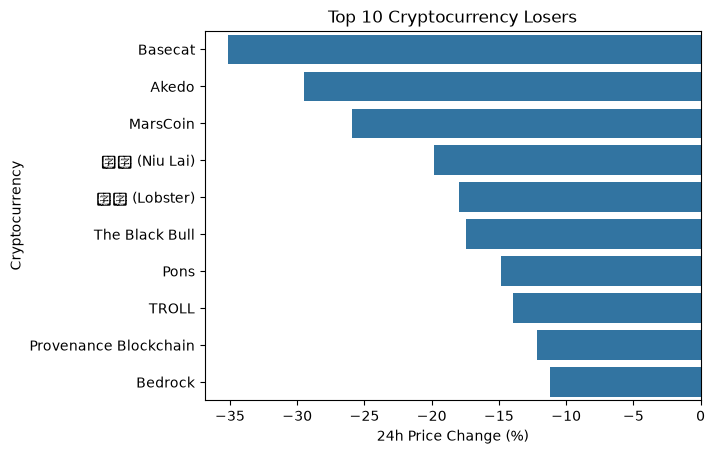

In [40]:
top_losers = df.nsmallest(10, 'price_change_percentage_24h')

sns.barplot(
    data=top_losers,
    x='price_change_percentage_24h',
    y='name'
)

plt.title('Top 10 Cryptocurrency Losers')
plt.xlabel('24h Price Change (%)')
plt.ylabel('Cryptocurrency')
plt.show()

# 6. Trading volume

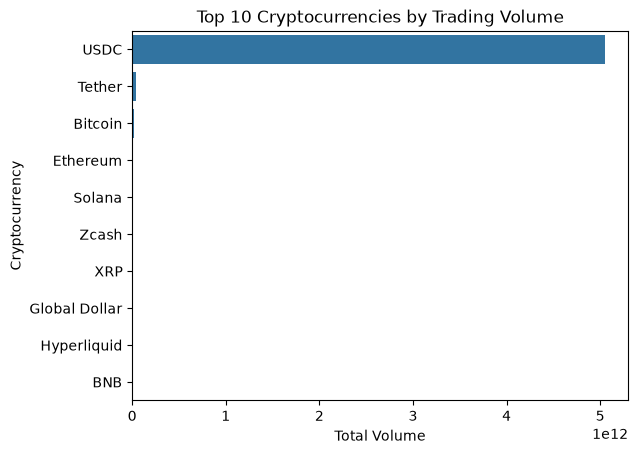

In [41]:
top_volume = df.nlargest(10, 'total_volume')

sns.barplot(
    data=top_volume,
    x='total_volume',
    y='name'
)

plt.title('Top 10 Cryptocurrencies by Trading Volume')
plt.xlabel('Total Volume')
plt.ylabel('Cryptocurrency')
plt.show()

# 7. Market Cap vs Trading Volume

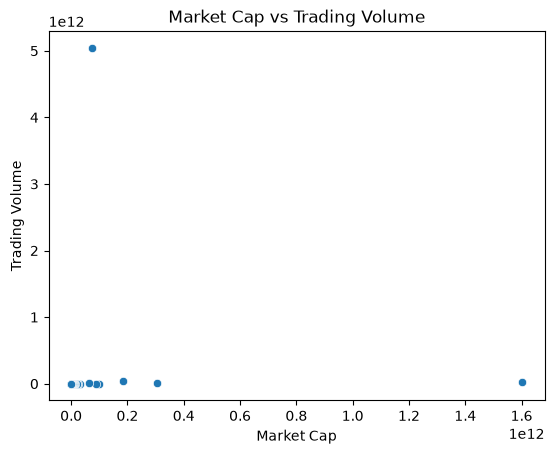

In [42]:
sns.scatterplot(
    data=df,
    x='market_cap',
    y='total_volume'
)

plt.title('Market Cap vs Trading Volume')
plt.xlabel('Market Cap')
plt.ylabel('Trading Volume')
plt.show()

# 8. Correlation heatmap

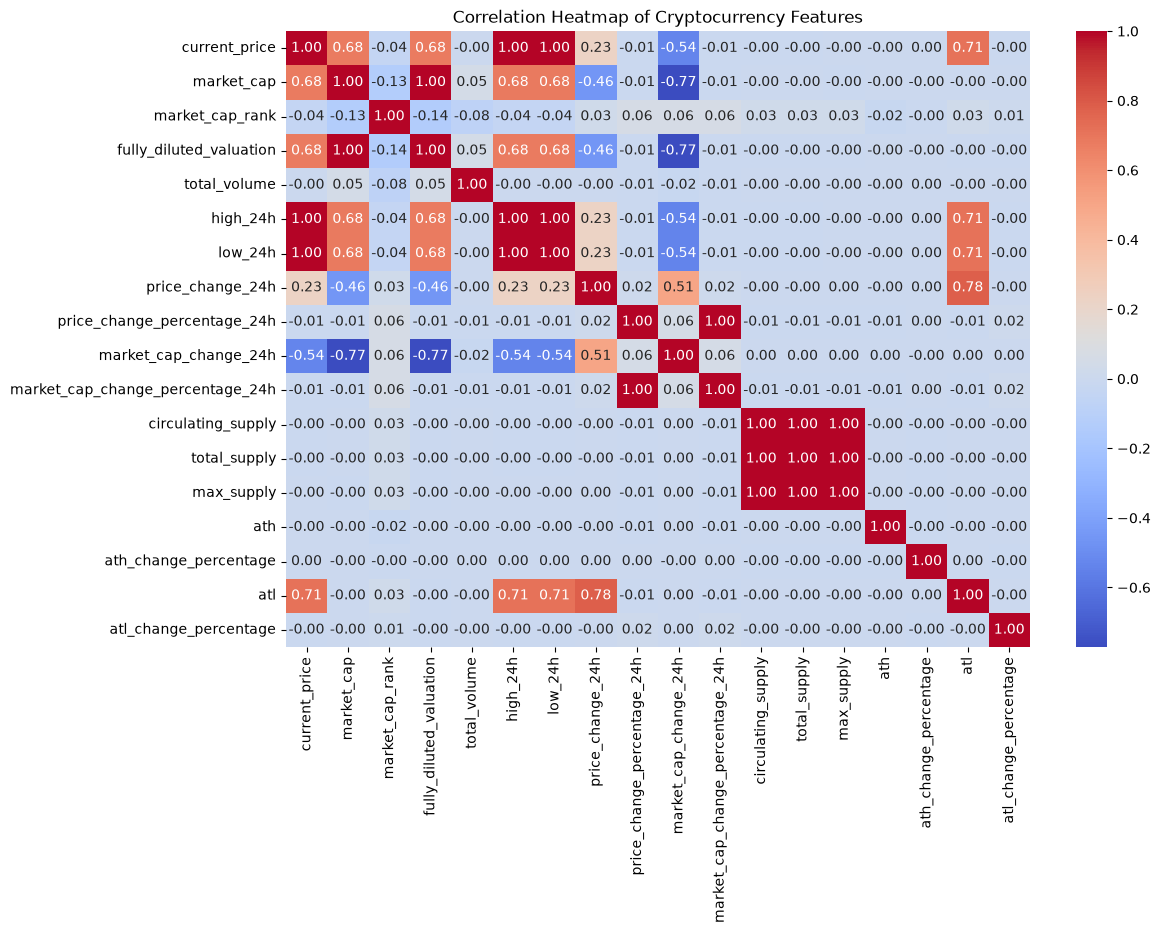

In [43]:
numeric_df = df.select_dtypes(include='number')

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Cryptocurrency Features')
plt.show()

# 9. Boxplots for detecting outliers

current_price

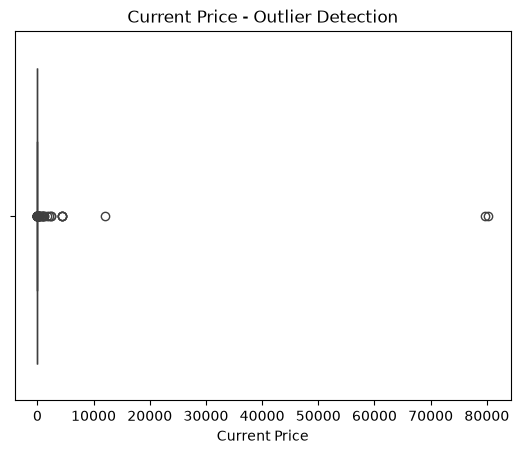

In [44]:
sns.boxplot(data=df, x='current_price')

plt.title('Current Price - Outlier Detection')
plt.xlabel('Current Price')
plt.show()

# For market_cap

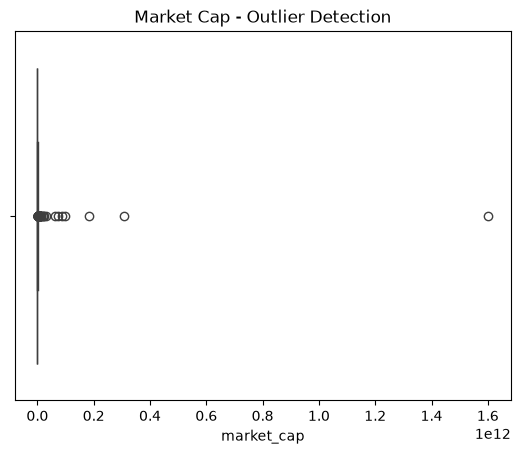

In [45]:
sns.boxplot(data=df, x='market_cap')
plt.title('Market Cap - Outlier Detection')
plt.show()

# 10. Supply analysis

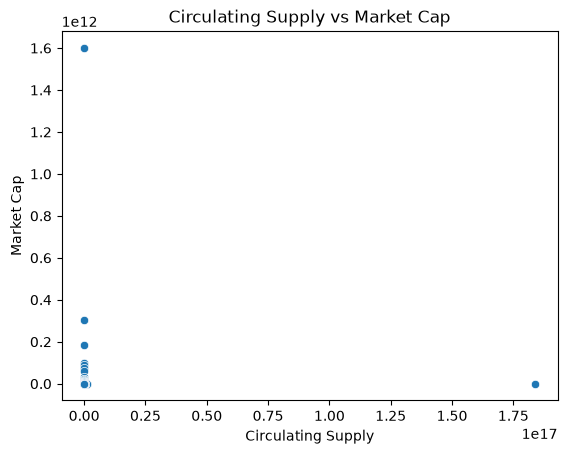

In [46]:
sns.scatterplot(
    data=df,
    x='circulating_supply',
    y='market_cap'
)

plt.title('Circulating Supply vs Market Cap')
plt.xlabel('Circulating Supply')
plt.ylabel('Market Cap')
plt.show()